# 05 · Diagnóstico e projeção do risco municipal

Este notebook utiliza o modelo municipal persistido em `models/` para avaliar o último ano observado, definir um ponto de operação, produzir a projeção do próximo ano disponível e executar verificações de robustez.

A avaliação binária considera somente linhas com `atingiu_meta_t`, `meta_t` e risco válidos. Linhas com `indicador_t` observado, mas sem meta, continuam na avaliação da regressão do nível e são excluídas apenas das métricas binárias.


In [1]:
from pathlib import Path
import os
import sys
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

SEED = 42


def localizar_raiz(inicio: Path | None = None) -> Path:
    atual = (inicio or Path.cwd()).resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / "data" / "processed").exists() and (candidato / "src").exists():
            return candidato
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


PROJECT_ROOT = localizar_raiz()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
REPORTS = PROJECT_ROOT / "reports"
IMAGES = PROJECT_ROOT / "images"
REPORTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)

from src.modeling.train_models import separar_features, EXCLUIR_MUNICIPIO
from src.evaluation.classification_metrics import (
    avaliar_classificacao,
    avaliar_regressao,
    risco_de_nao_atingir,
    matriz_confusao,
    limiar_por_recall_negativos,
    auc_da_ausencia,
)
from src.evaluation.model_validation import (
    validar_regressao_por_grupos,
    diferenca_bootstrap_pareada,
    predicao_por_uf_excluida,
)
from src.visualization.plot_style import (
    aplicar_estilo,
    salvar_figura,
    LARANJA,
    CINZA,
)

aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ARQ = PROCESSED / "base_analitica_municipio.parquet"
if not ARQ.exists():
    raise FileNotFoundError(ARQ)

abt = pd.read_parquet(ARQ)
observado = abt[abt["indicador_t"].notna()].copy()
observado["ano_alvo"] = pd.to_numeric(observado["ano_alvo"], errors="coerce").astype(int)
anos = sorted(observado["ano_alvo"].unique())
if len(anos) < 2:
    raise ValueError("São necessários pelo menos dois anos com indicador_t observado.")

ANO_TREINO = anos[-2]
ANO_TESTE = anos[-1]
treino = observado[observado["ano_alvo"] == ANO_TREINO].copy()
teste = observado[observado["ano_alvo"] == ANO_TESTE].copy()
print(f"Treino de diagnóstico: {ANO_TREINO} ({len(treino):,})")
print(f"Teste temporal: {ANO_TESTE} ({len(teste):,})")


Treino de diagnóstico: 2024 (5,352)
Teste temporal: 2025 (5,485)


## 1. Carregamento do modelo e dos metadados


In [2]:
MODEL_PATH = MODELS / "modelo_municipio.joblib"
META_PATH = MODELS / "modelo_municipio.json"

if not MODEL_PATH.exists() or not META_PATH.exists():
    raise FileNotFoundError("Treine primeiro o modelo municipal.")

modelo = joblib.load(MODEL_PATH)
meta = json.loads(META_PATH.read_text(encoding="utf-8"))
features = list(meta["features"])
residuos = np.asarray(meta.get("residuos_validacao", []), dtype=float)
residuos = residuos[np.isfinite(residuos)]

if residuos.size == 0:
    raise ValueError("O JSON do modelo não contém resíduos de validação válidos.")

print("Modelo:", meta.get("modelo"))
print("Features:", len(features))
print("Resíduos válidos:", len(residuos))


Modelo: random_forest
Features: 50
Resíduos válidos: 16194


## 2. Diagnóstico no último ano observado


Linhas com indicador observado: 5485
Linhas válidas para avaliação binária: 5439
Linhas sem meta ou target binário: 46
Métricas do nível: {'mae': 3.195988226184108, 'rmse': 4.646116761069824, 'r2': 0.917750493492505, 'vies': -0.25173708012122414, 'spearman': 0.963495917574818, 'n': 5485}
AUC do risco: 0.985


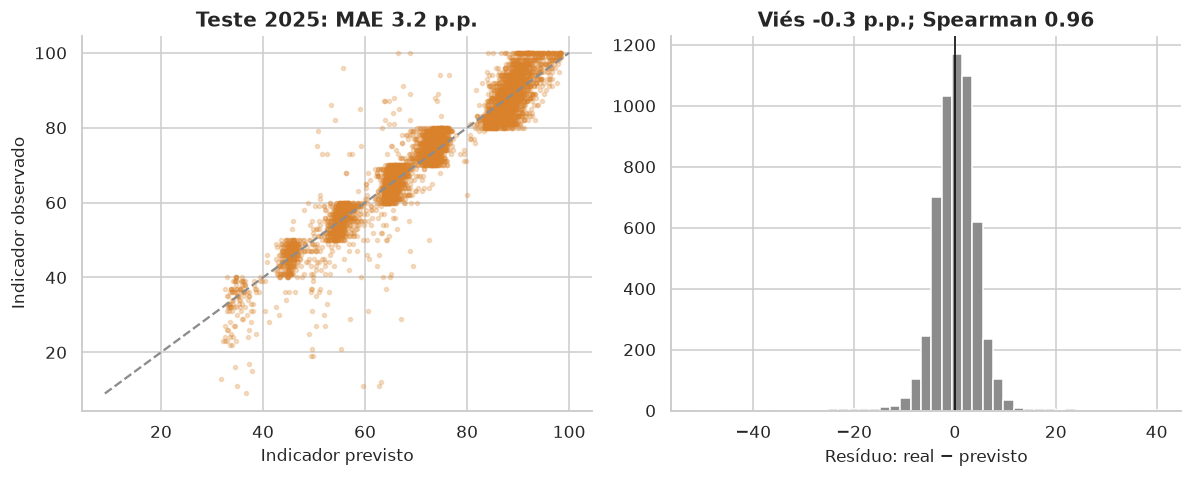

In [3]:
x_te, y_te = separar_features(
    teste,
    "indicador_t",
    EXCLUIR_MUNICIPIO,
    colunas_features=features,
)

pred_te = modelo.predict(x_te)
meta_teste = pd.to_numeric(teste.loc[x_te.index, "meta_t"], errors="coerce")
alvo_binario_teste = pd.to_numeric(
    teste.loc[x_te.index, "atingiu_meta_t"],
    errors="coerce",
)

risco_te = risco_de_nao_atingir(
    pred_te,
    meta_teste,
    residuos,
)

# Todas as linhas com indicador_t participam da avaliação do nível.
met_nivel = avaliar_regressao(y_te, pred_te)

# As métricas binárias exigem meta, target e risco observados.
mascara_classificacao = (
    alvo_binario_teste.notna()
    & meta_teste.notna()
    & np.isfinite(risco_te)
)

indices_teste_validos = x_te.index[mascara_classificacao]
y_clf = alvo_binario_teste.loc[mascara_classificacao].astype(int).to_numpy()
risco_te_clf = np.asarray(risco_te)[mascara_classificacao.to_numpy()]
p_atingir_te = 1 - risco_te_clf

if np.unique(y_clf).size < 2:
    auc_risco = np.nan
else:
    auc_risco = roc_auc_score(y_clf, p_atingir_te)

print("Linhas com indicador observado:", len(x_te))
print("Linhas válidas para avaliação binária:", int(mascara_classificacao.sum()))
print("Linhas sem meta ou target binário:", int((~mascara_classificacao).sum()))
print("Métricas do nível:", met_nivel)
print(f"AUC do risco: {auc_risco:.3f}" if np.isfinite(auc_risco) else "AUC do risco: não disponível")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(pred_te, y_te, s=7, alpha=0.25, color=LARANJA)
limites = [min(pred_te.min(), y_te.min()), max(pred_te.max(), y_te.max())]
axes[0].plot(limites, limites, ls="--", color=CINZA)
axes[0].set_xlabel("Indicador previsto")
axes[0].set_ylabel("Indicador observado")
axes[0].set_title(f"Teste {ANO_TESTE}: MAE {met_nivel['mae']:.1f} p.p.")

axes[1].hist(y_te.to_numpy() - pred_te, bins=45, color=CINZA)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_xlabel("Resíduo: real − previsto")
axes[1].set_title(f"Viés {met_nivel['vies']:.1f} p.p.; Spearman {met_nivel['spearman']:.2f}")

salvar_figura(fig, "05_diagnostico_modelo_municipal")
plt.show()


## 3. Validação OOF e ponto de operação


/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_meta_ultimo']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_meta_ultimo']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_meta_ultimo']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_

,auc_roc,auc_pr,acuracia,precisao,recall,f1,precisao_negativos,recall_negativos,limiar,taxa_base,n
validação,0.812,0.838,0.734,0.767,0.756,0.761,0.695,0.707,0.51,0.560,5347.0
teste,0.985,0.994,0.941,0.972,0.946,0.959,0.864,0.927,0.51,0.728,5439.0


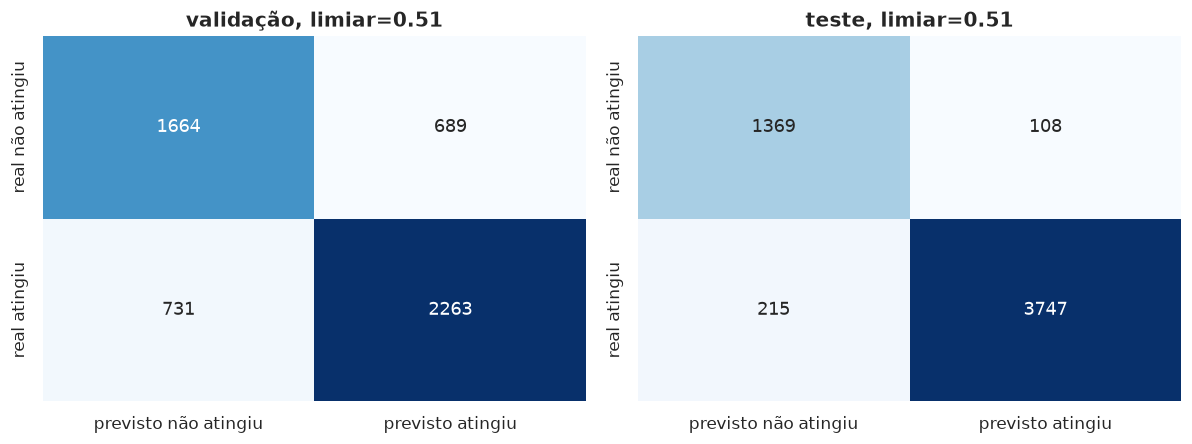

In [4]:
x_tr, y_tr = separar_features(
    treino,
    "indicador_t",
    EXCLUIR_MUNICIPIO,
    colunas_features=features,
)
g_tr = treino.loc[x_tr.index, "id_municipio"].to_numpy()

_, oof = validar_regressao_por_grupos(
    clone(modelo),
    x_tr,
    y_tr,
    g_tr,
    n_splits=min(5, pd.Series(g_tr).nunique()),
)

res_oof = y_tr.to_numpy(dtype=float) - oof
meta_oof = pd.to_numeric(treino.loc[x_tr.index, "meta_t"], errors="coerce")
alvo_oof = pd.to_numeric(treino.loc[x_tr.index, "atingiu_meta_t"], errors="coerce")
risco_oof = risco_de_nao_atingir(oof, meta_oof, res_oof)

mascara_oof = alvo_oof.notna() & meta_oof.notna() & np.isfinite(risco_oof)
y_oof_clf = alvo_oof.loc[mascara_oof].astype(int).to_numpy()
p_atingir_oof = 1 - np.asarray(risco_oof)[mascara_oof.to_numpy()]

limiar = limiar_por_recall_negativos(
    y_oof_clf,
    p_atingir_oof,
    recall_minimo=0.70,
)

metricas_operacao = pd.DataFrame(
    {
        "validação": avaliar_classificacao(y_oof_clf, p_atingir_oof, limiar),
        "teste": avaliar_classificacao(y_clf, p_atingir_te, limiar),
    }
).T

display(metricas_operacao.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (nome, y, p) in zip(
    axes,
    [
        ("validação", y_oof_clf, p_atingir_oof),
        ("teste", y_clf, p_atingir_te),
    ],
):
    mc = matriz_confusao(y, p, limiar, rotulos=("não atingiu", "atingiu"))
    sns.heatmap(mc, annot=True, fmt="g", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{nome}, limiar={limiar:.2f}")

salvar_figura(fig, "05_matriz_confusao_municipal")
plt.show()


## 4. Projeção para o próximo ano disponível


In [5]:
anos_abt = sorted(pd.to_numeric(abt["ano_alvo"], errors="coerce").dropna().astype(int).unique())
anos_futuros = [ano for ano in anos_abt if ano > ANO_TESTE]

if not anos_futuros:
    print("Não há ano futuro na base analítica. A projeção foi ignorada.")
    projecao = pd.DataFrame()
else:
    ANO_PROJECAO = anos_futuros[0]
    projecao = abt[
        abt["ano_alvo"].eq(ANO_PROJECAO)
        & abt["meta_t"].notna()
    ].copy()

    faltantes = [coluna for coluna in features if coluna not in projecao.columns]
    if faltantes:
        raise KeyError(f"Features ausentes na projeção: {faltantes}")

    x_proj = projecao[features].copy()
    categoricas = x_proj.select_dtypes(
        include=["object", "string", "category", "bool", "boolean"]
    ).columns
    for coluna in categoricas:
        x_proj[coluna] = x_proj[coluna].astype("string")

    projecao["indicador_previsto"] = modelo.predict(x_proj)
    projecao["folga_prevista_pp"] = projecao["indicador_previsto"] - projecao["meta_t"]
    projecao["risco_nao_atingir"] = risco_de_nao_atingir(
        projecao["indicador_previsto"],
        projecao["meta_t"],
        residuos,
    )

    colunas_ranking = [
        coluna
        for coluna in [
            "ano_alvo",
            "id_municipio",
            "nome_municipio",
            "sigla_uf",
            "rede",
            "indicador_t1",
            "meta_t",
            "indicador_previsto",
            "folga_prevista_pp",
            "risco_nao_atingir",
        ]
        if coluna in projecao.columns
    ]

    ranking = (
        projecao[colunas_ranking]
        .sort_values("risco_nao_atingir", ascending=False)
        .reset_index(drop=True)
    )
    ranking.insert(0, "posicao", np.arange(1, len(ranking) + 1))
    ranking.to_csv(
        REPORTS / f"municipios_risco_{ANO_PROJECAO}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    display(ranking.head(20).round(3))
    print(f"Ano projetado: {ANO_PROJECAO}")
    print(f"Registros projetados: {len(ranking):,}")


,posicao,ano_alvo,id_municipio,nome_municipio,sigla_uf,rede,indicador_t1,meta_t,indicador_previsto,folga_prevista_pp,risco_nao_atingir
0,1,2026,4310553,Itacurubi,RS,municipal,21.0,80.0,38.320,-41.68,0.998
1,2,2026,4307401,Esmeralda,RS,municipal,36.0,80.0,38.638,-41.362,0.998
2,3,2026,4300638,Amaral Ferrador,RS,municipal,25.0,75.0,35.671,-39.329,0.998
3,4,2026,4301909,Barra do Ribeiro,RS,municipal,38.0,74.0,36.545,-37.455,0.996
4,5,2026,4314209,Pedro Osório,RS,municipal,37.0,73.0,36.230,-36.77,0.996
5,6,2026,4317707,Santo Antônio das Missões,RS,municipal,40.0,76.0,39.785,-36.215,0.996
6,7,2026,4310702,Itatiba do Sul,RS,municipal,47.0,80.0,44.185,-35.815,0.996
7,8,2026,4319604,São Sepé,RS,municipal,30.0,80.0,44.403,-35.597,0.995
8,9,2026,4303400,Caiçara,RS,municipal,40.0,79.0,44.189,-34.811,0.995
9,10,2026,3116001,Chalé,MG,municipal,36.0,80.0,45.392,-34.608,0.995


Ano projetado: 2026
Registros projetados: 5,477


## 5. Comparação com regras simples


In [6]:
regras = {}

if "salto_necessario" in teste.columns:
    serie_salto = pd.to_numeric(
        teste.loc[indices_teste_validos, "salto_necessario"],
        errors="coerce",
    )
    regras["avanço necessário"] = -serie_salto.fillna(serie_salto.median()).to_numpy()

if "indicador_t1" in teste.columns:
    serie_indicador = pd.to_numeric(
        teste.loc[indices_teste_validos, "indicador_t1"],
        errors="coerce",
    )
    regras["indicador anterior"] = serie_indicador.fillna(serie_indicador.median()).to_numpy()

grupos_teste_validos = teste.loc[
    indices_teste_validos,
    "id_municipio",
].to_numpy()

linhas_comparacao = []
for nome, score in regras.items():
    comparacao = diferenca_bootstrap_pareada(
        y_clf,
        p_atingir_te,
        score,
        grupos_teste_validos,
        roc_auc_score,
        n_reamostras=300,
        seed=SEED,
        nivel=0.95,
    )
    linhas_comparacao.append({"regra": nome, **comparacao})

comparacao_regras = pd.DataFrame(linhas_comparacao)
display(comparacao_regras.round(3))
comparacao_regras.to_csv(
    REPORTS / "robustez_modelo_vs_regras.csv",
    index=False,
)


,regra,metrica_a,metrica_b,diferenca,ic_inferior,ic_superior,n_reamostras_validas
0,avanço necessário,0.985,0.741,0.244,0.230,0.257,300
1,indicador anterior,0.985,0.642,0.342,0.328,0.359,300


## 6. Diagnóstico de ausência de dados


In [7]:
alvo_ausencia = pd.to_numeric(
    treino.loc[x_tr.index, "atingiu_meta_t"],
    errors="coerce",
)
mascara_ausencia = alvo_ausencia.notna()

auc_ausencia = auc_da_ausencia(
    x_tr.loc[mascara_ausencia],
    alvo_ausencia.loc[mascara_ausencia].astype(int),
)

display(auc_ausencia.head(15).round(3))


,variavel,ausentes,auc_ausencia
0,indicador_t1,115,0.517
1,nivel_t1,115,0.517
2,participacao_t1,115,0.517
3,salto_necessario,115,0.517
4,pc_nivel_8,2362,0.511
5,pc_nivel_7,437,0.508
6,pc_nivel_2,314,0.508
7,pc_nivel_6,166,0.507
8,ideb_ideb_observado_ultimo,235,0.506
9,ideb_ideb_nota_portugues_ultimo,233,0.505


## 7. Extrapolação para UF não vista


In [8]:
uf_treino = treino.loc[x_tr.index, "sigla_uf"]
mascara_uf = uf_treino.notna()

pred_louo = predicao_por_uf_excluida(
    clone(modelo),
    x_tr.loc[mascara_uf],
    y_tr.loc[mascara_uf],
    uf_treino.loc[mascara_uf],
    regressao=True,
)

met_louo = avaliar_regressao(
    y_tr.loc[mascara_uf],
    pred_louo,
)

meta_louo = pd.to_numeric(
    treino.loc[x_tr.index[mascara_uf], "meta_t"],
    errors="coerce",
)
alvo_louo = pd.to_numeric(
    treino.loc[x_tr.index[mascara_uf], "atingiu_meta_t"],
    errors="coerce",
)
residuos_louo = y_tr.loc[mascara_uf].to_numpy() - pred_louo
risco_louo = risco_de_nao_atingir(pred_louo, meta_louo, residuos_louo)

mascara_louo_clf = alvo_louo.notna() & meta_louo.notna() & np.isfinite(risco_louo)
y_louo_clf = alvo_louo.loc[mascara_louo_clf].astype(int).to_numpy()
p_louo = 1 - np.asarray(risco_louo)[mascara_louo_clf.to_numpy()]
auc_louo = roc_auc_score(y_louo_clf, p_louo) if np.unique(y_louo_clf).size > 1 else np.nan

print("Métricas leave-one-UF-out:", met_louo)
print(f"AUC do risco com UF excluída: {auc_louo:.3f}" if np.isfinite(auc_louo) else "AUC indisponível")


/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_meta_ultimo']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_meta_ultimo']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_meta_ultimo']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_

Métricas leave-one-UF-out: {'mae': 10.076288336610215, 'rmse': 13.052830815011344, 'r2': 0.5401413905203074, 'vies': 0.6286850126588952, 'spearman': 0.725505511102607, 'n': 5352}
AUC do risco com UF excluída: 0.718


/home/linux/miniconda3/envs/teste_2/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['ideb_ideb_meta_ultimo']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


## 8. Estabilidade da lista projetada


In [9]:
if not projecao.empty:
    rng = np.random.default_rng(SEED)
    n_reamostras = 300
    frequencia = np.zeros(len(projecao))

    for _ in range(n_reamostras):
        residuos_reamostrados = rng.choice(
            residuos,
            size=len(residuos),
            replace=True,
        )
        risco_reamostrado = risco_de_nao_atingir(
            projecao["indicador_previsto"],
            projecao["meta_t"],
            residuos_reamostrados,
        )
        frequencia += risco_reamostrado >= 0.5

    frequencia /= n_reamostras
    estabilidade = pd.DataFrame(
        {
            "id_municipio": projecao["id_municipio"].to_numpy(),
            "frequencia_na_lista": frequencia,
        }
    )
    estabilidade.to_csv(
        REPORTS / f"estabilidade_lista_{ANO_PROJECAO}.csv",
        index=False,
    )

    resumo_estabilidade = pd.Series(
        {
            "núcleo (>=95%)": int((frequencia >= 0.95).sum()),
            "franja (5% a 95%)": int(((frequencia > 0.05) & (frequencia < 0.95)).sum()),
            "fora (<=5%)": int((frequencia <= 0.05).sum()),
        }
    )
    display(resumo_estabilidade.to_frame("quantidade"))


,quantidade
núcleo (>=95%),1985
franja (5% a 95%),32
fora (<=5%),3460


## 9. Registro final


In [10]:
def para_json(valor):
    if isinstance(valor, dict):
        return {str(chave): para_json(item) for chave, item in valor.items()}
    if isinstance(valor, (list, tuple, set)):
        return [para_json(item) for item in valor]
    if isinstance(valor, np.ndarray):
        return [para_json(item) for item in valor.tolist()]
    if isinstance(valor, np.generic):
        return valor.item()
    if isinstance(valor, pd.Timestamp):
        return valor.isoformat()
    if valor is pd.NA:
        return None
    if isinstance(valor, float) and not np.isfinite(valor):
        return None
    return valor


registro = {
    "modelo": meta.get("modelo"),
    "ano_treino_diagnostico": int(ANO_TREINO),
    "ano_teste_diagnostico": int(ANO_TESTE),
    "linhas_nivel_teste": int(len(x_te)),
    "linhas_risco_teste": int(mascara_classificacao.sum()),
    "metricas_nivel_teste": met_nivel,
    "auc_risco_teste": auc_risco,
    "limiar_probabilidade_atingir": limiar,
    "metricas_operacao": metricas_operacao.to_dict(orient="index"),
    "leave_one_uf_out": {
        **met_louo,
        "auc_risco": auc_louo,
    },
}

if not projecao.empty:
    registro["ano_projecao"] = int(ANO_PROJECAO)
    registro["registros_projetados"] = int(len(projecao))
    registro["risco_maior_igual_50_pct"] = int(
        (projecao["risco_nao_atingir"] >= 0.5).sum()
    )

registro_json = para_json(registro)
(REPORTS / "diagnostico_modelo_municipal.json").write_text(
    json.dumps(
        registro_json,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

print("Relatórios atualizados em reports/.")


Relatórios atualizados em reports/.


## 10. Limitações e uso responsável

- A probabilidade é condicionada às features e à distribuição histórica dos resíduos; não representa garantia causal.
- Mudanças nacionais ou estaduais podem deslocar o nível do indicador entre anos.
- Linhas sem meta podem ser avaliadas como regressão do nível, mas não entram nas métricas de atingimento.
- O teste com UF não vista avalia extrapolação, cenário diferente do uso nacional com todas as UFs representadas.
- O ranking deve apoiar triagem e análise técnica, não decisões automáticas ou sanções.
- O modelo deve ser reavaliado sempre que um novo ano observado for incorporado.
